# 03 - Storage cost attribution by feature

**Business question.** Storage is the fastest-growing infrastructure cost for the IPTV platform.
Which viewer features drive it, and is the spend proportional to how much those features are used?

**Definitions.**
* *Storage cost* = GB stored per day x tier price (USD per GB-month / 30), from
  `storage_usage_daily.csv` and `storage_rate_card.csv`.
* *Incremental storage* = everything beyond the short live delivery buffer (`LIVE_BUFFER`), i.e.
  the storage that exists only because of StartOver, catch-up, cloud DVR and VOD.
* *Usage* = viewing sessions (non-zap) and viewing hours by playback mode, from the session fact
  table built in notebook 01.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("../src").resolve()))
import sessionize as sz

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
RAW, PROC, FIG = Path("../data/raw"), Path("../data/processed"), Path("../reports/figures")

sessions, _ = sz.build_sessions(RAW / "stb_events.csv.gz", cache=PROC / "fact_session.csv.gz")
usage = pd.read_csv(RAW / "storage_usage_daily.csv", dtype={"channel_id": "string"})
rates = pd.read_csv(RAW / "storage_rate_card.csv")
channels = pd.read_csv(RAW / "channels.csv")
usage = usage.merge(rates[["storage_tier", "usd_per_gb_month"]], on="storage_tier", how="left")
assert usage.usd_per_gb_month.notna().all()
usage["cost_usd"] = usage.stored_gb * usage.usd_per_gb_month / 30
n_days = usage.usage_date.nunique()
print(f"{len(usage):,} usage rows over {n_days} days | total storage cost in period: ${usage.cost_usd.sum():,.0f}")

12,936 usage rows over 28 days | total storage cost in period: $10,861


## 1. Cost vs. usage by feature

In [2]:
FEATURE_TO_MODE = {"LIVE_BUFFER": "LIVE", "STARTOVER": "STARTOVER", "CATCHUP": "CATCHUP",
                   "CLOUD_DVR": "CLOUD_DVR", "VOD": "VOD"}
cost = usage.groupby("feature").agg(avg_tb_stored=("stored_gb", lambda s: s.sum() / n_days / 1000),
                                    cost_usd=("cost_usd", "sum"))
viewing = sessions[~sessions.is_zap]
use = viewing.groupby("playback_mode").agg(sessions=("session_id", "size"), viewing_hours=("duration_sec", "sum"))
use["viewing_hours"] /= 3600

tbl = cost.join(use.rename(index={v: k for k, v in FEATURE_TO_MODE.items()}))
tbl["monthly_run_rate_usd"] = tbl.cost_usd / n_days * 30
inc = tbl.drop(index="LIVE_BUFFER")
tbl["share_of_incremental_cost"] = inc.cost_usd / inc.cost_usd.sum()
tbl["share_of_sessions"] = tbl.sessions / tbl.sessions.sum()
tbl["share_of_viewing_hours"] = tbl.viewing_hours / tbl.viewing_hours.sum()
tbl["cost_per_1k_sessions"] = tbl.cost_usd / tbl.sessions * 1000
tbl["cost_per_viewing_hour"] = tbl.cost_usd / tbl.viewing_hours
order = ["LIVE_BUFFER", "STARTOVER", "CATCHUP", "CLOUD_DVR", "VOD"]
tbl = tbl.loc[order]
tbl.round(4)

,avg_tb_stored,cost_usd,sessions,viewing_hours,monthly_run_rate_usd,share_of_incremental_cost,share_of_sessions,share_of_viewing_hours,cost_per_1k_sessions,cost_per_viewing_hour
feature,,,,,,,,,,
LIVE_BUFFER,2.5409,106.7169,722626,337567.1100,114.3395,NaN,0.7750,0.7753,0.1477,0.0003
STARTOVER,25.2177,1059.1432,52106,24274.0197,1134.7963,0.0985,0.0559,0.0558,20.3267,0.0436
CATCHUP,155.6227,3050.2044,83243,38900.9983,3268.0762,0.2836,0.0893,0.0893,36.6422,0.0784
CLOUD_DVR,217.9016,4270.8718,46396,21510.9983,4575.9340,0.3971,0.0498,0.0494,92.0526,0.1985
VOD,121.1275,2374.0988,28028,13149.6544,2543.6773,0.2208,0.0301,0.0302,84.7045,0.1805


In [3]:
so_cu = ["STARTOVER", "CATCHUP"]
headline = pd.Series({
    "StartOver + catch-up share of incremental storage cost": tbl.loc[so_cu, "share_of_incremental_cost"].sum(),
    "StartOver + catch-up share of viewing sessions": tbl.loc[so_cu, "share_of_sessions"].sum(),
    "StartOver + catch-up share of viewing hours": tbl.loc[so_cu, "share_of_viewing_hours"].sum(),
    "cost ratio vs. usage (cost share / session share)": tbl.loc[so_cu, "share_of_incremental_cost"].sum()
                                                       / tbl.loc[so_cu, "share_of_sessions"].sum(),
    "incremental monthly run-rate (USD, sample)": tbl.drop(index="LIVE_BUFFER").monthly_run_rate_usd.sum(),
})
headline.round(3).rename("value").to_frame()

,value
StartOver + catch-up share of incremental storage cost,0.382
StartOver + catch-up share of viewing sessions,0.145
StartOver + catch-up share of viewing hours,0.145
cost ratio vs. usage (cost share / session share),2.632
"incremental monthly run-rate (USD, sample)",11522.484


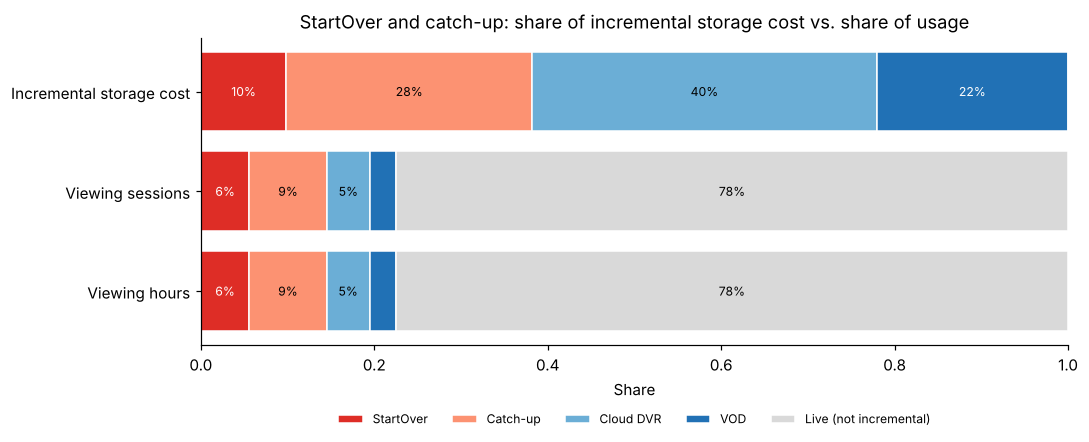

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.2))
feat = ["STARTOVER", "CATCHUP", "CLOUD_DVR", "VOD", "LIVE_BUFFER"]
colors = {"STARTOVER": "#de2d26", "CATCHUP": "#fc9272", "CLOUD_DVR": "#6baed6", "VOD": "#2171b5", "LIVE_BUFFER": "#d9d9d9"}
bars = {
    "Incremental storage cost": tbl.share_of_incremental_cost.fillna(0),
    "Viewing sessions": tbl.share_of_sessions,
    "Viewing hours": tbl.share_of_viewing_hours,
}
for i, (label, s) in enumerate(bars.items()):
    left = 0
    for f in feat:
        v = s.get(f, 0)
        ax.barh(i, v, left=left, color=colors[f], label=f if i == 0 else None, edgecolor="white")
        if v > 0.04:
            ax.text(left + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=8,
                    color="white" if f in ("STARTOVER", "VOD") else "black")
        left += v
ax.set_yticks(range(len(bars)), list(bars)); ax.invert_yaxis()
ax.set_xlim(0, 1); ax.set_xlabel("Share")
ax.set_title("StartOver and catch-up: share of incremental storage cost vs. share of usage")
ax.legend(ncol=5, frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18),
          labels=["StartOver", "Catch-up", "Cloud DVR", "VOD", "Live (not incremental)"])
fig.tight_layout(); fig.savefig(FIG / "03_storage_cost_vs_usage.png", bbox_inches="tight"); plt.show()

## 2. Where the catch-up and StartOver archive goes unused

StartOver and catch-up keep a rolling archive for every enabled channel regardless of demand. Two
questions: (a) how concentrated is usage across channels, and (b) how much of the retention window
is actually watched? Each time-shifted session carries `content_age_min`, the minutes between the
original broadcast and playback.

Bottom half of channels by time-shift usage: 7.0% of StartOver/catch-up sessions but 46.3% of their storage cost


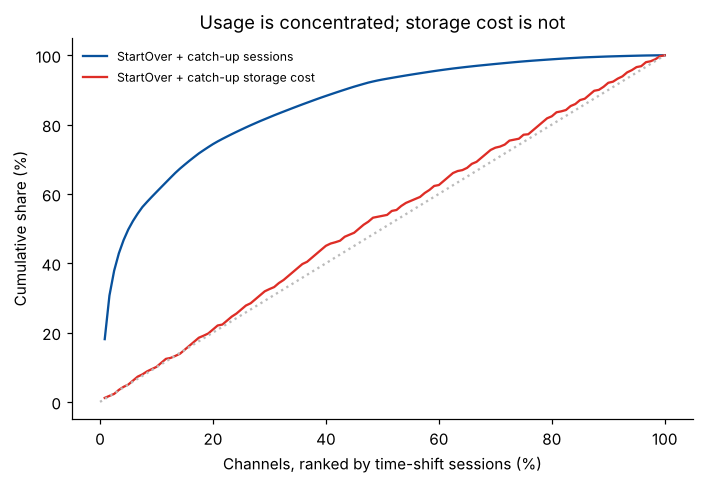

In [5]:
ch_cost = (usage[usage.feature.isin(so_cu)].groupby(["channel_id", "feature"]).cost_usd.sum()
           .unstack(fill_value=0))
ch_use = (viewing[viewing.playback_mode.isin(so_cu)].groupby(["channel_id", "playback_mode"]).size()
          .unstack(fill_value=0))
ch = (ch_cost.add_suffix("_cost").join(ch_use.add_suffix("_sessions"), how="left").fillna(0)
      .join(channels.set_index("channel_id")[["genre", "catchup_window_days", "startover_enabled"]]))
ch["total_cost"] = ch.STARTOVER_cost + ch.CATCHUP_cost
ch["total_sessions"] = ch.STARTOVER_sessions + ch.CATCHUP_sessions
ch = ch.sort_values("total_sessions", ascending=False)
cum = pd.DataFrame({"channels": np.arange(1, len(ch) + 1) / len(ch),
                    "sessions": ch.total_sessions.cumsum() / ch.total_sessions.sum(),
                    "cost": ch.total_cost.cumsum() / ch.total_cost.sum()})
q = int(np.ceil(0.5 * len(ch)))
print(f"Bottom half of channels by time-shift usage: {1 - cum.sessions.iloc[len(ch) - q - 1]:.1%} of StartOver/catch-up "
      f"sessions but {1 - cum.cost.iloc[len(ch) - q - 1]:.1%} of their storage cost")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(cum.channels * 100, cum.sessions * 100, color="#08519c", label="StartOver + catch-up sessions")
ax.plot(cum.channels * 100, cum.cost * 100, color="#de2d26", label="StartOver + catch-up storage cost")
ax.plot([0, 100], [0, 100], color="#bbbbbb", ls=":")
ax.set_xlabel("Channels, ranked by time-shift sessions (%)"); ax.set_ylabel("Cumulative share (%)")
ax.set_title("Usage is concentrated; storage cost is not"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "03_channel_concentration.png", bbox_inches="tight"); plt.show()

,value
catch-up sessions on 7-day channels,72065.0000
share watched within 24h of broadcast,0.6099
share watched within 3 days,0.9420
share watched after day 3,0.0580
StartOver sessions,52106.0000
share within 2h of broadcast,1.0000
share within 4h of broadcast,1.0000


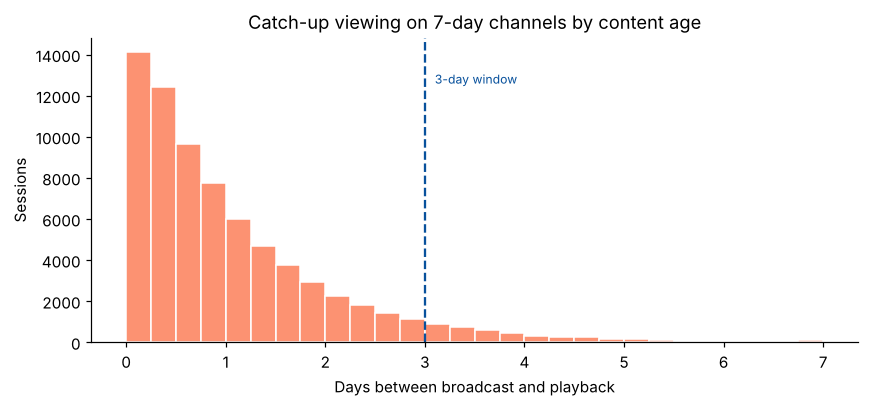

In [6]:
age = viewing[viewing.playback_mode.isin(so_cu)].merge(channels[["channel_id", "catchup_window_days"]], on="channel_id")
cu7 = age[(age.playback_mode == "CATCHUP") & (age.catchup_window_days == 7)]
so = age[age.playback_mode == "STARTOVER"]
age_stats = pd.Series({
    "catch-up sessions on 7-day channels": len(cu7),
    "  share watched within 24h of broadcast": (cu7.content_age_min <= 1440).mean(),
    "  share watched within 3 days": (cu7.content_age_min <= 3 * 1440).mean(),
    "  share watched after day 3": (cu7.content_age_min > 3 * 1440).mean(),
    "StartOver sessions": len(so),
    "  share within 2h of broadcast": (so.content_age_min <= 120).mean(),
    "  share within 4h of broadcast": (so.content_age_min <= 240).mean(),
})
display(age_stats.round(4).rename("value").to_frame())

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(cu7.content_age_min / 1440, bins=np.arange(0, 7.25, 0.25), color="#fc9272", edgecolor="white")
ax.axvline(3, color="#08519c", ls="--"); ax.text(3.1, ax.get_ylim()[1] * 0.85, "3-day window", color="#08519c", fontsize=8)
ax.set_title("Catch-up viewing on 7-day channels by content age")
ax.set_xlabel("Days between broadcast and playback"); ax.set_ylabel("Sessions")
fig.tight_layout(); fig.savefig(FIG / "03_catchup_content_age.png", bbox_inches="tight"); plt.show()

## 3. Retention scenarios

Storage scales linearly with the retention window (GB = bitrate ladder x hours retained), so the
saving from shortening a window is proportional. Sessions "at risk" are those whose content age
exceeds the new window; they would need to fall back to cloud DVR or VOD.

* **A. StartOver hot buffer 24h -> 4h** on all channels.
* **B. Catch-up 7 -> 3 days** on the 7-day channels in the bottom half by catch-up sessions per
  TB stored.
* **C. Catch-up 7 -> 3 days** on all 7-day channels.

In [7]:
incr_month = tbl.drop(index="LIVE_BUFFER").monthly_run_rate_usd.sum()
so_month = tbl.loc["STARTOVER", "monthly_run_rate_usd"]
cu_month_by_ch = ch.CATCHUP_cost / n_days * 30
ch["catchup_sessions_per_tb"] = ch.CATCHUP_sessions / (
    usage[usage.feature == "CATCHUP"].groupby("channel_id").stored_gb.mean().reindex(ch.index) / 1000)
seven = ch[ch.catchup_window_days == 7]
low = seven[seven.catchup_sessions_per_tb <= seven.catchup_sessions_per_tb.median()].index
total_viewing = len(viewing)

def scenario(name, saving, at_risk):
    return {"scenario": name, "monthly saving (USD, sample)": saving,
            "saving as % of incremental storage": saving / incr_month,
            "sessions at risk": int(at_risk), "at-risk % of time-shift sessions": at_risk / tbl.loc[so_cu, "sessions"].sum(),
            "at-risk % of all viewing sessions": at_risk / total_viewing}

scen = pd.DataFrame([
    scenario("A. StartOver 24h -> 4h", so_month * (1 - 4 / 24), (so.content_age_min > 240).sum()),
    scenario("B. Catch-up 7d -> 3d, low-use channels", cu_month_by_ch.loc[low].sum() * 4 / 7,
             (cu7[cu7.channel_id.isin(low)].content_age_min > 3 * 1440).sum()),
    scenario("C. Catch-up 7d -> 3d, all 7-day channels", cu_month_by_ch.loc[seven.index].sum() * 4 / 7,
             (cu7.content_age_min > 3 * 1440).sum()),
])
combo = scen.iloc[[0, 1]].sum(numeric_only=True)
scen.loc[len(scen)] = {"scenario": "A + B combined", **combo.to_dict()}
scen.round(4)

,scenario,"monthly saving (USD, sample)",saving as % of incremental storage,sessions at risk,at-risk % of time-shift sessions,at-risk % of all viewing sessions
0,A. StartOver 24h -> 4h,945.6636,0.0821,0.0,0.0000,0.0000
1,"B. Catch-up 7d -> 3d, low-use channels",864.2952,0.0750,349.0,0.0026,0.0004
2,"C. Catch-up 7d -> 3d, all 7-day channels",1696.5387,0.1472,4181.0,0.0309,0.0045
3,A + B combined,1809.9588,0.1571,349.0,0.0026,0.0004


In [8]:
tbl.round(4).to_csv(PROC / "storage_cost_by_feature.csv")
ch.round(3).to_csv(PROC / "storage_timeshift_by_channel.csv")
scen.round(4).to_csv(PROC / "storage_retention_scenarios.csv", index=False)
print("saved")

saved


## Findings

* **StartOver and catch-up drive 38.2% of incremental storage cost** (StartOver 9.8%, catch-up
  28.4%) but carry only **14.5% of viewing sessions** (and 14.5% of viewing hours). That is 2.6x
  their share of usage. Cloud DVR (39.7%) and VOD (22.1%) account for the rest.
* Per viewing hour, catch-up storage costs USD 0.078 and StartOver USD 0.044, against USD 0.0003
  for live. The archive is kept for every enabled channel whether or not anyone watches it.
* Usage is concentrated but the cost is not: the half of channels with the least time-shift use
  carry 7.0% of StartOver/catch-up sessions but 46.3% of the storage cost.
* On 7-day catch-up channels, 94.2% of catch-up viewing happens within 3 days of broadcast.
  StartOver viewing in the sample is entirely within 2 hours of broadcast, but the platform keeps
  24 hours in hot storage.
* Retention scenarios: cutting the StartOver hot buffer to 4 hours and catch-up to 3 days on
  low-use channels saves 15.7% of incremental storage, with 349 sessions (0.04% of viewing) at
  risk. Cutting catch-up to 3 days on all 7-day channels saves 14.7% on its own, with 0.45% of
  viewing at risk.
* Dollar amounts come from an illustrative rate card applied to the sample. The shares and ratios
  are what carry over to full scale.